# 物体槽注入 VL-JEPA:slots_v1、检查与分析、slots_v2

**目的**:把 dino.txt 找到的"题目里的物体在哪"注入现有 VL-JEPA(不蒸馏),看空间题能否提升。

**物体槽**:题目里每个物体名,由冻结的 dino.txt 在 8 帧里选出分数最高的 4 个 patch(候选),点提示头(box05)把每个 patch 升成 3D 位置(米)。全程不训练,预先算好写进 manifest。

| 部分 | 内容 | 结果文件 |
|---|---|---|
| 1 | slots_v1 结果:槽的位置向量加在名字 token 上 | `experiments/slots_v1/results` |
| 2 | slots_v1 检查与分析:槽向量诊断、逐层检查 | `experiments/slots_v1/results`、`experiments/layer_diagnosis/results` |
| 3 | slots_v2 结果与分析:每个物体一个单独的 token + 对比损失 | `experiments/slots_v2/results`、`experiments/layer_diagnosis/results` |
| 4 | 另一个评测集 SPAR-Bench:hardneg_v1 和 slots_v2 | `experiments/sparbench_eval/results` |

三个模型的数据、损失和训练步数相同(6870 步,3 张卡),初始权重相同;对照组是 hardneg_v1(没有槽)。

## 总结

- **slots_v1 失败**:真槽和换成别的题的槽准确率相同。槽向量被学成一个比 token 长 20 倍的常数,模型只用"它在不在"。
- **逐层检查**:题目 token 在看场景 token(换场景后隐状态变 30–58%),但换场景只掉 2–3 个点;任何一层的名字 token 都读不出物体位置。slots_v1 注入的位置在第 1 层就丢了一半。
- **slots_v2 部分有效**:物体 token 的输出依赖场景(认出自己位置的准确率真场景 26%,换场景 1%),槽的内容第一次被用于答题(留出集相对距离题,真槽 45.2,换槽 38.6)。
- **但定位不准、VSI-Bench 没动**:物体 token 的位置误差 1.93 m(总是答平均位置约 2.1 m,点提示头 0.57 m);VSI-Bench test 33.6(hardneg_v1 33.7)。
- **SPAR-Bench**:hardneg_v1 27.0、slots_v2 23.4,随机 27.1。两个模型都没学过这些题型,这个评测集区分不了它们。
- 每个题型只有 100–1000 题,3 个点以内的差别不算数。

In [1]:
import json
import pandas as pd
import matplotlib.pyplot as plt
load = lambda path: json.load(open(path))
h = load("../../hardneg_v1/results/eval_final.json")
v1 = load("../../slots_v1/results/eval_final.json")
v2 = load("../results/eval_final.json")
MODES = ["real", "shuffled", "zero", "slots_swapped", "slots_none", "all_shuffled"]
acc = lambda v: None if v is None else 100 * (v["acc"] if isinstance(v, dict) else v)

def table(s, ds, keep=lambda k: True):
    rows = {}
    for k, v in s["real"][ds].items():
        if not keep(k):
            continue
        row = {"题数": v.get("rows") if isinstance(v, dict) else None,
               "随机": 100 * v["chance"] if isinstance(v, dict) else None,
               "hardneg_v1 real": acc(h["real"][ds].get(k)), "hardneg_v1 shuffled": acc(h["shuffled"][ds].get(k))}
        row.update({m: acc(s[m][ds][k]) for m in MODES})
        rows[k] = row
    return pd.DataFrame(rows).T.dropna(axis=1, how="all").astype(float).round(1)

def curves(run):
    read = lambda p: pd.DataFrame([json.loads(l) for l in open(p)])
    t, n = read(f"../../{run}/results/train_log.jsonl"), read(f"../../{run}/results/hardneg_log.jsonl")
    slot = "slot_acc" in n
    fig, ax = plt.subplots(1, 3 if slot else 2, figsize=(16 if slot else 11, 3.5))
    a = t.dropna(subset=["loss"]); ax[0].plot(a.step, a.loss, label="train infonce")
    if "val_loss" in t: b = t.dropna(subset=["val_loss"]); ax[0].plot(b.step, b.val_loss, label="val")
    ax[0].set_xlabel("step"); ax[0].set_ylabel("loss"); ax[0].legend()
    a = n.dropna(subset=["hard_acc"]); ax[1].plot(a.step, a.hard_acc, label="train hard_acc")
    if "val_hard_acc" in n: b = n.dropna(subset=["val_hard_acc"]); ax[1].plot(b.step, b.val_hard_acc, label="val hard_acc")
    ax[1].set_xlabel("step"); ax[1].legend()
    if slot:
        a = n.dropna(subset=["slot_acc"]); ax[2].plot(a.step, a.slot_acc, label="train: 物体 token 认出自己位置")
        if "val_slot_acc" in n: b = n.dropna(subset=["val_slot_acc"]); ax[2].plot(b.step, b.val_slot_acc, label="val")
        ax[2].set_xlabel("step"); ax[2].legend()
    plt.tight_layout()

LAYERS = None
def layer(run):
    return load(f"../../layer_diagnosis/results/{run}.json")

---

# 第 1 部分 slots_v1 结果

**做法**:`SlotEncoder` 把一个槽的 4 个候选位置和置信度变成一个向量,加到题目中该物体名的 token 上,再进 Llama predictor。

**对照**(同一个 checkpoint):

| 名称 | 场景 token | 槽 |
|---|---|---|
| real | 本题的 | 本题的 |
| shuffled / zero | 别的题的 / 全零 | 本题的 |
| slots_swapped | 本题的 | 别的题的 |
| slots_none | 本题的 | 不给 |
| all_shuffled | 别的题的 | 别的题的 |

## 1.1 留出集,长答案(训练时的答案格式)

In [2]:
table(v1, "holdout", lambda k: k.startswith("long/"))

,题数,随机,hardneg_v1 real,hardneg_v1 shuffled,real,shuffled,zero,slots_swapped,slots_none,all_shuffled
long/all,6786.0,29.9,46.7,44.1,47.4,43.9,44.3,47.5,28.7,43.8
long/spar/appearance_order,1000.0,25.0,37.7,28.8,40.8,33.3,34.1,40.5,22.6,33.3
long/spar/spatial_imagination_oc_video_hard,1000.0,31.2,44.8,43.7,41.8,41.8,41.9,42.6,42.4,42.2
long/spar/spatial_imagination_oo_video_hard,1000.0,13.3,23.6,23.3,24.3,22.5,23.1,24.1,22.9,22.0
long/vsi590k/appearance_order,632.0,25.0,45.7,40.8,47.5,41.3,40.7,47.6,16.9,40.0
long/vsi590k/relative_count,154.0,33.3,55.2,45.5,56.5,40.9,37.0,55.8,27.3,42.9
long/vsi590k/relative_direction_object,1000.0,37.3,46.1,45.8,45.7,43.5,44.4,45.7,41.0,43.2
long/vsi590k/relative_distance_object,1000.0,25.0,42.5,41.4,46.0,40.4,41.1,46.0,25.4,40.7
long/vsi590k/relative_size_object,1000.0,50.0,84.7,83.6,84.5,84.3,84.9,84.5,25.8,84.1


real = slots_swapped;slots_none 在带物体名的题型上掉到随机以下。

## 1.2 留出集,短答案

In [3]:
table(v1, "holdout", lambda k: k.startswith("short/"))

,题数,随机,hardneg_v1 real,hardneg_v1 shuffled,real,shuffled,zero,slots_swapped,slots_none,all_shuffled
short/all,3786.0,35.2,41.9,40.8,33.9,33.9,36.7,34.2,33.9,34.4
short/vsi590k/appearance_order,632.0,25.0,42.6,36.2,35.8,32.1,31.2,36.1,21.0,33.1
short/vsi590k/relative_count,154.0,33.3,21.4,21.4,25.3,29.2,31.2,30.5,18.8,31.8
short/vsi590k/relative_direction_object,1000.0,37.3,46.5,45.6,26.8,31.1,40.0,26.4,36.1,30.9
short/vsi590k/relative_distance_object,1000.0,25.0,30.9,31.0,24.6,24.7,24.3,25.4,26.4,25.7
short/vsi590k/relative_size_object,1000.0,50.0,50.9,51.6,50.6,47.7,50.2,50.3,49.6,47.8


比 hardneg_v1 低 8 个点,方向题从 46.5 掉到 26.8。

## 1.3 VSI-Bench test

In [4]:
table(v1, "vsibench_test_posed_f8")

,hardneg_v1 real,hardneg_v1 shuffled,real,shuffled,zero,slots_swapped,slots_none,all_shuffled
all,33.7,33.2,33.4,32.4,33.8,33.8,27.2,32.6
type/obj_appearance_order,40.9,40.1,41.4,40.6,31.2,40.5,27.8,39.8
type/object_rel_direction_easy,50.8,50.0,51.7,48.3,49.2,53.3,50.0,52.5
type/object_rel_direction_hard,27.3,27.7,26.4,27.3,43.7,29.0,10.0,26.0
type/object_rel_direction_medium,29.6,32.1,34.6,33.7,44.4,35.0,44.0,35.4
type/object_rel_distance,26.2,24.9,24.3,22.7,26.2,25.0,21.9,23.2
type/route_planning,33.3,31.1,23.3,23.3,23.3,23.3,22.2,22.2


参考:按规则直接用槽算答案(`experiments/slot_vsibench_check`):方向 easy 77.5 / medium 70.4 / hard 64.9,相对距离 44.4。

## 1.4 VSI-Bench debiased

In [5]:
table(v1, "vsibench_debiased_posed_f8")

,hardneg_v1 real,hardneg_v1 shuffled,real,shuffled,zero,slots_swapped,slots_none,all_shuffled
all,35.0,34.3,30.2,30.9,26.6,30.1,29.5,30.2
type/obj_appearance_order,36.2,36.8,33.3,32.1,25.2,33.3,30.2,32.1
type/object_rel_direction_easy,51.3,50.4,50.4,45.3,47.9,50.4,51.3,47.9
type/object_rel_direction_hard,23.9,19.4,11.9,22.4,20.9,13.4,26.9,22.4
type/object_rel_direction_medium,45.9,43.2,37.8,40.5,21.6,35.1,24.3,35.1
type/object_rel_distance,25.8,26.3,22.5,25.8,22.0,22.0,21.5,23.0
type/route_planning,34.9,28.6,17.5,19.0,19.0,17.5,17.5,17.5


## 1.5 训练曲线

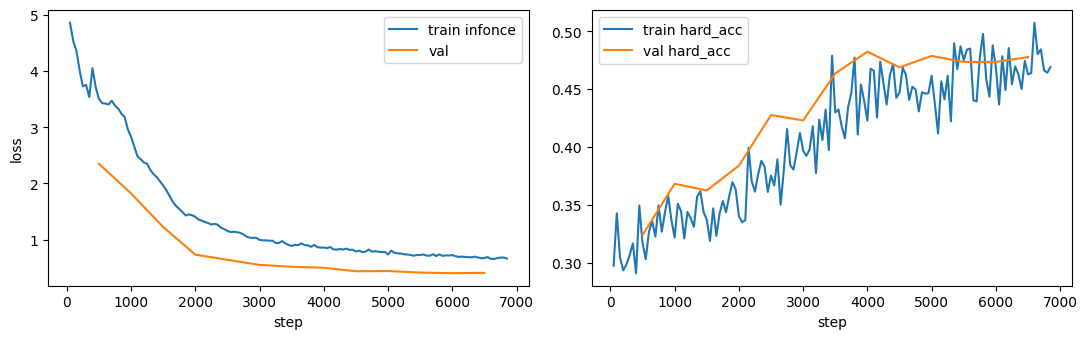

In [6]:
curves("slots_v1")

## 1 结论

- 模型没有用槽里的位置:real 和 slots_swapped 在所有题型上相同(留出集 47.4 对 47.5,VSI-Bench 33.4 对 33.8)。
- 模型只用了"这里有个槽向量":不给槽时留出集长答案从 47.4 掉到 28.7,低于随机(29.9)。
- VSI-Bench 没有提升(33.4,hardneg_v1 33.7);留出集短答案 41.9 → 33.9,路径规划 33.3 → 23.3。

---

# 第 2 部分 slots_v1 检查与分析

## 2.1 训练后的槽向量是否随位置变化

`jepa3d/tools/diagnose_slot_encoder.py`,留出集全部 23,828 个槽;预测向量部分取 8 个 batch。

In [7]:
d = load("../../slots_v1/results/diagnose_slot_encoder.json")
v = d["vectors"]
print("槽向量平均长度 %.2f,其中所有槽共有的常数向量长度 %.2f,各槽不同的部分平均长度 %.2f(占平方长度的 %.2f%%)"
      % (v["norm_mean"], v["mean_vector_norm"], v["varying_part_norm_mean"], 100 * v["varying_share_of_squared_norm"]))
print("名字 token 平均长度 %.2f,加上去的槽向量最长 %.1f" % (d["query_token_norm_mean"], d["largest_added_vector_norm"]))
print("从槽向量读回最佳候选位置的中位误差 %.2f m(总是答平均位置:%.2f m)"
      % (v["position_readout_m"]["ridge_0.01"], v["position_readout_m"]["mean"]))
pd.DataFrame({"槽向量的相对变化": pd.Series(v["relative_change"]),
              "预测向量的余弦距离(中位数)": pd.Series(d["prediction_cosine_distance_median"])}).round(4)

槽向量平均长度 19.52,其中所有槽共有的常数向量长度 19.52,各槽不同的部分平均长度 0.86(占平方长度的 0.32%)
名字 token 平均长度 0.94,加上去的槽向量最长 24.8
从槽向量读回最佳候选位置的中位误差 1.06 m(总是答平均位置:2.08 m)


,槽向量的相对变化,预测向量的余弦距离(中位数)
between_rows,NaN,0.9851
conf_minus_2,0.1218,NaN
conf_plus_2,0.1286,NaN
none,NaN,0.8572
other_rows,NaN,0.0054
other_slot,0.0623,NaN
shift_0.25m,0.0115,0.0002
shift_0.5m,0.0132,0.0002
shift_1.0m,0.0154,0.0002
shift_2.0m,0.0196,0.0004


- 槽向量几乎是常数:99.7% 的平方长度来自所有槽共有的一个向量,它比名字 token 长约 20 倍,把名字本身盖住。
- 位置只留下很小的痕迹:挪 2 米向量变 2%;置信度的影响比位置大(±2 变 12–13%)。
- predictor 不理会这点痕迹:换成别的题的槽,预测只动 0.005;不给槽动 0.86,接近两道不同题之间的 0.99。

## 2.2 逐层检查:题目和场景 token 有没有交互

`jepa3d/tools/diagnose_layers.py`,slots_v1 和 hardneg_v1 各取留出集 1,024 行。隐状态取 predictor 每一层之后;"input" 是进第 1 层之前。

**切断注意力**:在所有层屏蔽"题目→场景"(q>s)或"场景→题目"(s>q)的注意力,看预测向量的变化(余弦距离)和长答案准确率。

In [8]:
def knockout(runs, keys):
    out = {}
    for run in runs:
        k = layer(run)["knockout"]
        out[(run, "预测变化")] = {key: k[key]["prediction_moved"] for key in keys if key in k}
        out[(run, "准确率")] = {key: None if k[key]["accuracy"] is None else 100 * k[key]["accuracy"] for key in keys if key in k}
    return pd.DataFrame(out).round(3)
knockout(["slots_v1", "hardneg_v1"], ["none", "scene of another row", "q>s all", "s>q all", "slots shifted 2 m",
                                      "slots of other names", "two rows"])

slots_v1         hardneg_v1        
                         预测变化     准确率       预测变化     准确率
none                    0.000  46.094      0.000  44.629
scene of another row    0.349  43.262      0.349  42.285
q>s all                 0.971  36.035      0.962  38.672
s>q all                 0.027  47.461      0.024  45.020
slots shifted 2 m       0.000  46.484        NaN     NaN
slots of other names    0.005  46.680        NaN     NaN
two rows                0.978     NaN      1.003     NaN

- 题目 token 在看场景:换场景后预测向量变 0.35(两道不同的题是 1.0)。
- 但内容对答题帮助小:换场景只掉 2–3 个点;切断注意力掉 6–10 个点,模型更依赖"有场景 token 在场"。
- 场景 token 看不看题目,对答案没有影响(答案由题目 token 池化得到)。

**注意力占比**:题目 token 的注意力落在场景 token 上的比例(均匀分配时约 0.97)。

In [9]:
def attention(runs):
    return pd.DataFrame({run: [a["question_on_scene"] for a in layer(run)["attention"]] for run in runs},
                        index=[f"layer {i}" for i in range(1, 9)]).T.round(2)
attention(["slots_v1", "hardneg_v1"])

,layer 1,layer 2,layer 3,layer 4,layer 5,layer 6,layer 7,layer 8
slots_v1,0.86,0.87,0.56,0.63,0.67,0.62,0.49,0.50
hardneg_v1,0.96,0.87,0.80,0.75,0.68,0.74,0.51,0.36


## 2.3 哪几层在读场景

单层切断"题目→场景"注意力后的长答案准确率(1,024 行,约 ±1.5 个点的噪声)。

In [10]:
def single(runs, direction):
    out = {}
    for run in runs:
        k = layer(run)["knockout"]
        if f"{direction} layer 1" not in k:
            continue
        out[run] = {"不切断": 100 * k["none"]["accuracy"],
                    **{f"layer {i}": 100 * k[f"{direction} layer {i}"]["accuracy"] for i in range(1, 9)},
                    "全部层": 100 * k[f"{direction} all"]["accuracy"]}
    return pd.DataFrame(out).T.round(1)
single(["slots_v1", "hardneg_v1"], "q>s")

,不切断,layer 1,layer 2,layer 3,layer 4,layer 5,layer 6,layer 7,layer 8,全部层
slots_v1,46.1,41.8,47.5,37.7,47.4,47.7,46.3,43.3,42.5,36.0
hardneg_v1,44.6,44.0,44.3,46.1,45.6,43.3,44.5,44.8,41.8,38.7


slots_v1 主要在第 1、3 层和最后两层读场景;hardneg_v1 只有最后一层明显。

换场景后,题目 token 的隐状态在每一层的相对变化:

In [11]:
def change(runs, key):
    return pd.DataFrame({run: layer(run)["hidden_change"][key] for run in runs if key in layer(run)["hidden_change"]},
                        index=layer(runs[0])["layers"]).T.round(3)
change(["slots_v1", "hardneg_v1"], "scene of another row: question tokens")

,input,layer 1,layer 2,layer 3,layer 4,layer 5,layer 6,layer 7,layer 8
slots_v1,0.0,0.305,0.557,0.512,0.519,0.584,0.564,0.497,0.428
hardneg_v1,0.0,0.042,0.099,0.215,0.298,0.338,0.359,0.419,0.429


## 2.4 位置信息在哪一层丢

从每层名字 token 的平均隐状态线性读回该物体最佳候选的位置(岭回归,一半名字拟合,另一半算中位误差,米)。

In [12]:
def readback(runs, part="name_tokens"):
    out = {run: [x["error_m"] for x in layer(run)["readback"][part]] for run in runs if part in layer(run)["readback"]}
    frame = pd.DataFrame(out, index=layer(runs[0])["layers"]).T.round(2)
    frame["总是答平均位置"] = round(layer(runs[0])["readback"]["mean"], 2)
    return frame
readback(["slots_v1", "hardneg_v1"])

,input,layer 1,layer 2,layer 3,layer 4,layer 5,layer 6,layer 7,layer 8,总是答平均位置
slots_v1,1.29,1.70,1.82,1.92,2.01,2.01,2.05,2.08,2.10,2.12
hardneg_v1,2.11,1.88,1.80,1.84,1.89,1.88,1.92,2.00,2.07,2.12


槽位置挪 2 米或换成别的名字的槽时,slots_v1 各类 token 隐状态的相对变化:

In [13]:
pd.DataFrame({k: v for k, v in layer("slots_v1")["hidden_change"].items() if k.startswith("slots")},
             index=layer("slots_v1")["layers"]).T.round(3)

,input,layer 1,layer 2,layer 3,layer 4,layer 5,layer 6,layer 7,layer 8
slots shifted 2 m: name tokens,0.008,0.026,0.039,0.047,0.048,0.046,0.044,0.043,0.038
slots shifted 2 m: other question tokens,0.000,0.003,0.006,0.032,0.034,0.034,0.033,0.034,0.032
slots shifted 2 m: scene tokens,0.000,0.001,0.001,0.020,0.021,0.020,0.017,0.019,0.018
slots of other names: name tokens,0.025,0.091,0.136,0.161,0.164,0.155,0.147,0.142,0.121
slots of other names: other question tokens,0.000,0.005,0.019,0.109,0.115,0.114,0.111,0.113,0.105
slots of other names: scene tokens,0.000,0.001,0.003,0.071,0.072,0.068,0.057,0.064,0.063


## 2 结论

- **slots_v1 的注入**:位置在输入处还能读出一部分(1.29 m),第 1 层就丢了一半,最后一层完全读不出(2.10 m,和答平均位置一样)。挪 2 米只让名字 token 变 4%。
- **hardneg_v1**:任何一层都读不出物体位置(最好 1.80 m,只看场景整体是 1.85 m)。模型从未定位过题目里的物体。
- **交互存在但不带来位置**:题目 token 在看场景,但看到的内容不足以回答"哪个物体在哪"。
- **对设计的含义**:注入的东西要和 token 同量级、单独成 token、内容和场景 token 同源,并且要有一个直接针对它输出的损失。这就是 slots_v2。

---

# 第 3 部分 slots_v2 结果与分析

**做法**(参考 SR-3D 的区域 token 和 CVP 的 target-affinity token):

- **单独的物体 token**:每个物体名一个新 token,位置编码与名字最后一个 token 相同,长度和普通 token 同量级,带类型标记。
- **内容是视觉特征,不含坐标**:4 个候选 patch 各取冻结 DINOv2 的 patch 特征和该像素的射线,加上 dino.txt 置信度。
- **对比损失**:predictor 在物体 token 上的输出,要从同一 batch 所有物体的 3D 位置里认出自己最佳候选的位置(InfoNCE)。位置不在输入里,只能沿射线从场景 token 读出来。
- 其余与 hardneg_v1 相同。训练 5 h 10 min(每步多一次 DINOv2 前向)。

## 3.1 物体 token 的定位

In [14]:
pd.DataFrame({m: {"认出自己位置的准确率 %": 100 * v2[m]["object_tokens"]["acc"], "位置误差 m(各 batch 中位数的平均)": v2[m]["object_tokens"]["error_m"]}
              for m in MODES if v2[m].get("object_tokens")}).T.round(2)

,认出自己位置的准确率 %,位置误差 m(各 batch 中位数的平均)
real,26.04,1.93
shuffled,1.20,2.85
zero,1.17,4.33
slots_swapped,1.00,2.81
all_shuffled,0.71,2.85


- 真场景 26%,换场景或换槽都掉到 1%:物体 token 的输出依赖场景内容和自己的 patch。
- 误差 1.93 m,只比答平均位置(约 2.1 m)好一点;冻结 3DRAE 上的点提示头是 0.57 m。

## 3.2 留出集,长答案

In [15]:
table(v2, "holdout", lambda k: k.startswith("long/"))

,题数,随机,hardneg_v1 real,hardneg_v1 shuffled,real,shuffled,zero,slots_swapped,slots_none,all_shuffled
long/all,6786.0,29.9,46.7,44.1,48.1,44.5,44.4,46.8,37.8,43.6
long/spar/appearance_order,1000.0,25.0,37.7,28.8,42.5,31.6,32.3,40.2,30.1,30.2
long/spar/spatial_imagination_oc_video_hard,1000.0,31.2,44.8,43.7,43.0,42.4,43.4,42.1,41.8,42.3
long/spar/spatial_imagination_oo_video_hard,1000.0,13.3,23.6,23.3,23.5,24.1,23.1,24.4,24.6,23.9
long/vsi590k/appearance_order,632.0,25.0,45.7,40.8,49.2,40.2,41.1,47.2,20.6,38.0
long/vsi590k/relative_count,154.0,33.3,55.2,45.5,57.8,40.3,26.6,57.8,49.4,44.8
long/vsi590k/relative_direction_object,1000.0,37.3,46.1,45.8,46.6,46.1,47.1,48.0,47.7,48.2
long/vsi590k/relative_distance_object,1000.0,25.0,42.5,41.4,45.2,40.8,40.5,38.6,36.7,35.8
long/vsi590k/relative_size_object,1000.0,50.0,84.7,83.6,85.9,85.1,84.5,85.6,54.7,84.9


## 3.3 留出集,短答案

In [16]:
table(v2, "holdout", lambda k: k.startswith("short/"))

,题数,随机,hardneg_v1 real,hardneg_v1 shuffled,real,shuffled,zero,slots_swapped,slots_none,all_shuffled
short/all,3786.0,35.2,41.9,40.8,40.6,39.6,40.1,39.1,34.9,38.3
short/vsi590k/appearance_order,632.0,25.0,42.6,36.2,42.6,37.3,38.1,40.8,20.1,36.6
short/vsi590k/relative_count,154.0,33.3,21.4,21.4,37.0,31.2,20.8,40.9,27.9,39.6
short/vsi590k/relative_direction_object,1000.0,37.3,46.5,45.6,37.9,40.0,41.5,37.7,39.9,37.3
short/vsi590k/relative_distance_object,1000.0,25.0,30.9,31.0,33.8,32.5,33.6,27.5,21.5,29.0
short/vsi590k/relative_size_object,1000.0,50.0,50.9,51.6,49.5,48.9,49.5,50.6,53.6,49.4


## 3.4 VSI-Bench test

In [17]:
table(v2, "vsibench_test_posed_f8")

,hardneg_v1 real,hardneg_v1 shuffled,real,shuffled,zero,slots_swapped,slots_none,all_shuffled
all,33.7,33.2,33.6,33.9,29.5,33.1,26.5,34.6
type/obj_appearance_order,40.9,40.1,37.5,37.2,29.0,40.1,21.0,40.6
type/object_rel_direction_easy,50.8,50.0,53.3,57.5,48.3,52.5,50.0,52.5
type/object_rel_direction_hard,27.3,27.7,15.6,13.0,8.2,14.7,8.2,15.2
type/object_rel_direction_medium,29.6,32.1,35.0,34.6,32.5,32.5,49.0,37.0
type/object_rel_distance,26.2,24.9,32.8,34.6,32.0,29.7,23.9,31.3
type/route_planning,33.3,31.1,26.7,27.8,38.9,27.8,34.4,32.2


## 3.5 VSI-Bench debiased

In [18]:
table(v2, "vsibench_debiased_posed_f8")

,hardneg_v1 real,hardneg_v1 shuffled,real,shuffled,zero,slots_swapped,slots_none,all_shuffled
all,35.0,34.3,33.7,35.8,34.5,35.5,30.6,34.8
type/obj_appearance_order,36.2,36.8,32.1,32.7,32.4,34.9,23.9,33.0
type/object_rel_direction_easy,51.3,50.4,53.8,59.0,47.0,54.7,48.7,52.1
type/object_rel_direction_hard,23.9,19.4,23.9,16.4,28.4,22.4,28.4,19.4
type/object_rel_direction_medium,45.9,43.2,35.1,35.1,45.9,40.5,29.7,35.1
type/object_rel_distance,25.8,26.3,29.2,34.9,27.8,30.1,28.7,32.1
type/route_planning,34.9,28.6,28.6,31.7,44.4,31.7,39.7,36.5


## 3.6 三个模型对比(real)

In [19]:
rows = {}
for ds, keys in (("holdout", ["long/all", "short/all", "long/vsi590k/relative_direction_object", "long/vsi590k/relative_distance_object"]),
                 ("vsibench_test_posed_f8", ["all", "type/object_rel_direction_easy", "type/object_rel_direction_medium",
                                             "type/object_rel_direction_hard", "type/object_rel_distance", "type/obj_appearance_order",
                                             "type/route_planning"])):
    for k in keys:
        rows[f"{ds.split('_')[0]}: {k}"] = {"hardneg_v1": acc(h["real"][ds][k]), "slots_v1": acc(v1["real"][ds][k]),
                                           "slots_v2": acc(v2["real"][ds][k]), "v2 换槽": acc(v2["slots_swapped"][ds][k]),
                                           "v2 换场景": acc(v2["shuffled"][ds][k])}
pd.DataFrame(rows).T.round(1)

,hardneg_v1,slots_v1,slots_v2,v2 换槽,v2 换场景
holdout: long/all,46.7,47.4,48.1,46.8,44.5
holdout: short/all,41.9,33.9,40.6,39.1,39.6
holdout: long/vsi590k/relative_direction_object,46.1,45.7,46.6,48.0,46.1
holdout: long/vsi590k/relative_distance_object,42.5,46.0,45.2,38.6,40.8
vsibench: all,33.7,33.4,33.6,33.1,33.9
vsibench: type/object_rel_direction_easy,50.8,51.7,53.3,52.5,57.5
vsibench: type/object_rel_direction_medium,29.6,34.6,35.0,32.5,34.6
vsibench: type/object_rel_direction_hard,27.3,26.4,15.6,14.7,13.0
vsibench: type/object_rel_distance,26.2,24.3,32.8,29.7,34.6
vsibench: type/obj_appearance_order,40.9,41.4,37.5,40.1,37.2


## 3.7 训练曲线

/tmp/ipykernel_394820/2749156222.py:38: UserWarning: Glyph 29289 (\N{CJK UNIFIED IDEOGRAPH-7269}) missing from current font.
  plt.tight_layout()
/tmp/ipykernel_394820/2749156222.py:38: UserWarning: Glyph 20307 (\N{CJK UNIFIED IDEOGRAPH-4F53}) missing from current font.
  plt.tight_layout()
/tmp/ipykernel_394820/2749156222.py:38: UserWarning: Glyph 35748 (\N{CJK UNIFIED IDEOGRAPH-8BA4}) missing from current font.
  plt.tight_layout()
/tmp/ipykernel_394820/2749156222.py:38: UserWarning: Glyph 20986 (\N{CJK UNIFIED IDEOGRAPH-51FA}) missing from current font.
  plt.tight_layout()
/tmp/ipykernel_394820/2749156222.py:38: UserWarning: Glyph 33258 (\N{CJK UNIFIED IDEOGRAPH-81EA}) missing from current font.
  plt.tight_layout()
/tmp/ipykernel_394820/2749156222.py:38: UserWarning: Glyph 24049 (\N{CJK UNIFIED IDEOGRAPH-5DF1}) missing from current font.
  plt.tight_layout()
/tmp/ipykernel_394820/2749156222.py:38: UserWarning: Glyph 20301 (\N{CJK UNIFIED IDEOGRAPH-4F4D}) missing from current font.

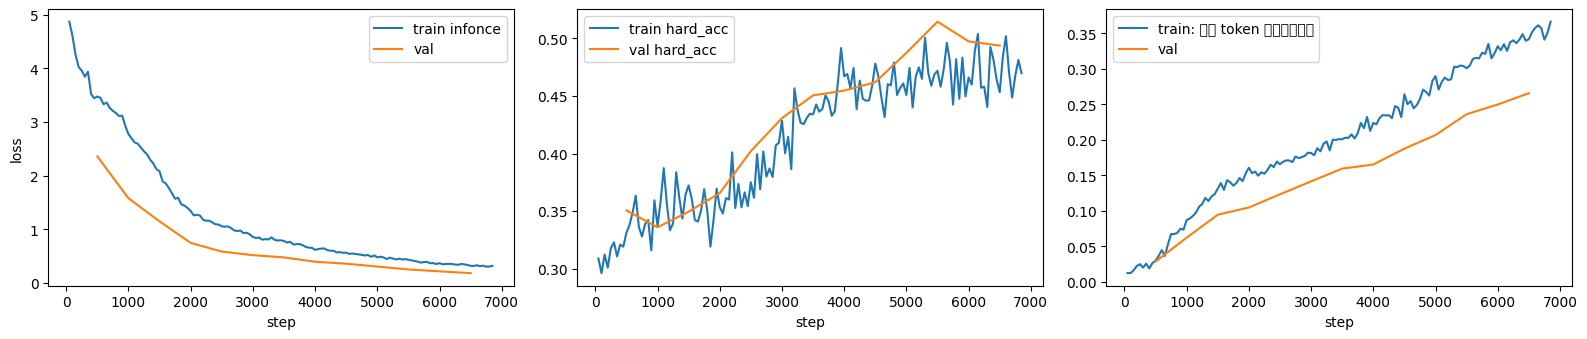

In [20]:
curves("slots_v2")

## 3.8 逐层检查(同 2.2–2.4 的工具,slots_v2,1,024 行)

多了一种切断:题目 token 不能看物体 token(q>o)。

In [21]:
knockout(["slots_v2", "slots_v1", "hardneg_v1"], ["none", "scene of another row", "slots of other names", "q>s all",
                                                  "s>q all", "q>o all", "two rows"])

slots_v2         slots_v1         hardneg_v1        
                         预测变化     准确率     预测变化     准确率       预测变化     准确率
none                    0.000  48.438    0.000  46.094      0.000  44.629
scene of another row    0.272  43.750    0.349  43.262      0.349  42.285
slots of other names    0.107  45.801    0.005  46.680        NaN     NaN
q>s all                 1.100  31.641    0.971  36.035      0.962  38.672
s>q all                 0.229  42.188    0.027  47.461      0.024  45.020
q>o all                 0.577  36.621      NaN     NaN        NaN     NaN
two rows                0.977     NaN    0.978     NaN      1.003     NaN

In [22]:
pd.concat({"q>s": single(["slots_v2"], "q>s"), "q>o": single(["slots_v2"], "q>o")})

,,layer 1,layer 2,layer 3,layer 4,layer 5,layer 6,layer 7,layer 8,不切断,全部层
q>s,slots_v2,44.8,44.6,44.4,45.8,49.0,47.6,47.7,43.7,48.4,31.6
q>o,slots_v2,48.6,48.1,48.0,41.5,48.9,49.1,49.1,48.7,48.4,36.6


位置读回(米):名字 token、物体 token。

In [23]:
pd.concat({"名字 token": readback(["slots_v2", "slots_v1", "hardneg_v1"]), "物体 token": readback(["slots_v2"], "object_tokens")})

input  layer 1  layer 2  layer 3  layer 4  layer 5  \
名字 token slots_v2     2.11     1.82     1.83     1.84     1.82     1.85   
         slots_v1     1.29     1.70     1.82     1.92     2.01     2.01   
         hardneg_v1   2.11     1.88     1.80     1.84     1.89     1.88   
物体 token slots_v2     1.93     1.73     1.74     1.74     1.69     1.56   

                     layer 6  layer 7  layer 8  总是答平均位置  
名字 token slots_v2       1.79     1.82     1.82     2.12  
         slots_v1       2.05     2.08     2.10     2.12  
         hardneg_v1     1.92     2.00     2.07     2.12  
物体 token slots_v2       1.47     1.45     1.43     2.12

换成别的名字的槽时,slots_v2 各类 token 隐状态的相对变化:

In [24]:
pd.DataFrame({k: v for k, v in layer("slots_v2")["hidden_change"].items()}, index=layer("slots_v2")["layers"]).T.round(3)

,input,layer 1,layer 2,layer 3,layer 4,layer 5,layer 6,layer 7,layer 8
scene of another row: question tokens,0.0,0.043,0.123,0.271,0.315,0.346,0.441,0.532,0.625
slots of other names: name tokens,0.0,0.001,0.006,0.103,0.189,0.232,0.312,0.379,0.419
slots of other names: other question tokens,0.0,0.001,0.006,0.098,0.175,0.219,0.297,0.357,0.382
slots of other names: scene tokens,0.0,0.001,0.002,0.010,0.044,0.079,0.126,0.207,0.272


## 3 结论

- **物体 token 被用上了**:所有层切断题目对物体 token 的注意力,准确率 48.4 → 36.6;只切第 4 层就掉到 41.5,题目 token 主要在第 4 层读物体 token。换成别的名字的槽,名字 token 和其他题目 token 的隐状态到最后一层变 40% 左右(slots_v1 是 3–12%)。
- **物体 token 里逐层积累位置**:读回误差从输入的 1.93 m 降到最后一层的 1.43 m。名字 token 仍读不出(1.82 m)。
- **答题上的收益小**:留出集长答案 48.1(hardneg_v1 46.7,slots_v1 47.4),真槽比换槽高 1.3;相对距离题真槽 45.2、换槽 38.6。短答案回到 40.6。
- **VSI-Bench 没有提升**:33.6。相对距离 32.8(hardneg_v1 26.2),但换场景后是 34.6,这个提升不来自场景。方向 hard 15.6(hardneg_v1 27.3),原因未查。
- **瓶颈**:定位太粗(1.4–1.9 m),不足以判断方向和距离。训练结束时物体 token 的准确率还在升(3.7 节),一个 epoch 没有收敛。

## 下一步(未做)

1. 物体 token 的损失训练更久,或先单独预训练这一项再联合训练。
2. 把点提示头读出的特征(已验证 0.57 m)直接放进物体 token,而不是让 predictor 从头学定位。
3. 查方向 hard 下降的原因。

---

# 第 4 部分 另一个评测集:SPAR-Bench

`data/spar3d_eval9k.jsonl`:7,870 道选择题,带相机位姿,ScanNet + ScanNet++,24 种题型,视角数 1、2、3 或 8。服务器上不用下载、又带位姿的评测集只有这一个(MMSI-Bench 没有位姿)。作业 `jepa3d/trainbatch/sparbench_eval.sbatch`,结果在 `experiments/sparbench_eval/results`。slots_v1 的 checkpoint 已删除,不参加。

注意:训练集只含 SPAR 的 5 种视频题型(8 帧);这里的题大多是 1–3 帧,带"红点、蓝点、第几帧"这类标记,模型没有见过。

In [25]:
types = load("../../sparbench_eval/results/types.json")
bh, b2 = load("../../sparbench_eval/results/hardneg_v1.json"), load("../../sparbench_eval/results/slots_v2.json")
total = sum(n for n, _, _ in types.values())
rows = {}
for key in ["all"] + sorted(k for k in b2["real"]["spar3d_eval9k"] if k != "all"):
    name = key.replace("type/", "")
    n, chance, views = types.get(name, [total, sum(n * c for n, c, _ in types.values()) / total, ""])
    row = {"题数": n, "视角数": "/".join(map(str, views)), "随机": round(100 * chance, 1)}
    row.update({f"hardneg_v1 {m}": round(100 * bh[m]["spar3d_eval9k"][key], 1) for m in ("real", "shuffled", "zero")})
    row.update({f"slots_v2 {m}": round(100 * b2[m]["spar3d_eval9k"][key], 1) for m in ("real", "shuffled", "zero", "slots_swapped", "slots_none")})
    rows[name] = row
pd.DataFrame(rows).T

,题数,视角数,随机,hardneg_v1 real,hardneg_v1 shuffled,hardneg_v1 zero,slots_v2 real,slots_v2 shuffled,slots_v2 zero,slots_v2 slots_swapped,slots_v2 slots_none
all,7870,,27.1,27.0,26.0,24.7,23.4,23.6,22.9,23.5,24.8
camera_motion_infer,328,2,25.0,29.6,26.2,27.1,29.0,26.5,29.0,28.4,29.6
depth_prediction_oc,335,1,25.0,19.7,18.2,16.7,26.3,33.4,27.2,30.7,31.0
depth_prediction_oc_mv,420,3,25.0,19.5,19.3,14.3,27.4,25.7,29.8,25.5,28.8
depth_prediction_oo,271,1,25.0,25.1,21.0,21.0,23.6,21.8,21.0,22.1,27.3
depth_prediction_oo_mv,355,3,25.0,34.4,32.7,31.8,29.6,28.2,20.0,28.7,26.2
distance_infer_center_oc,107,1,25.0,24.3,25.2,26.2,22.4,26.2,26.2,24.3,26.2
distance_infer_center_oc_mv,599,1/3,25.0,19.7,26.9,26.4,19.4,21.9,17.7,21.0,19.5
distance_infer_center_oo,288,1,50.0,46.2,51.7,49.0,48.3,50.0,52.4,48.3,50.0
distance_infer_center_oo_mv,376,3,50.0,49.7,50.8,50.5,52.9,52.4,53.5,50.0,49.2


## 4 结论

- **两个模型在 SPAR-Bench 上都在随机水平**:随机 27.1,hardneg_v1 27.0,slots_v2 23.4。真场景、换场景、全零场景之间没有差别。
- **这个评测集区分不了两个模型**:题型和视角数都在训练分布之外,结果反映的是"没学过这类题",不是空间能力的差别。
- **个别题型远低于随机**(slots_v2 的 obj_spatial_relation、spatial_imagination 只有 5–19%,四选一):说明模型对这些题的选项有固定偏向,和图像无关。room_size 79.5% 也与场景无关(换场景 89.0)。
- 要在别的评测集上得到有意义的数字,需要评测题型在训练里出现过,例如把 SPAR 的非视频题型加入训练,或用 VSI-Bench 里尚未用到的带位姿的部分。